# Raio-X do Mercado de Trabalho Industrial de Santa Catarina
**Equipe Kirasapiens Neurotech · Datathon UniSENAI 2026 · consultoria de dados para a FIESC**

> **Pergunta central:** quais regiões (municípios) e setores industriais de SC enfrentam apagão de mão de obra ou expansão acelerada, e como renda e escolaridade explicam esses gargalos?

> **Regra de dados:** o diagnóstico usa **apenas as bases fornecidas pelo desafio** (Novo CAGED MOV, base municipal de SC e dicionário de dados), mais a classificação de CBOs feita por IA a partir dessas mesmas bases. Fontes externas (regiões geográficas e malha do IBGE) ficam isoladas em `data/externos/` e aparecem só no **Apêndice bônus** e no filtro *Bônus* do painel.

Este notebook documenta **todo o pipeline**, da carga inicial e exclusão de registros inválidos até a comunicação com a IA e a exportação final que alimenta o painel (`dashboard/app.py`). O código reutilizável está em `backend/`.

| Etapa do guia | Onde está neste notebook | Código |
|---|---|---|
| Ingestão e validação (schema, inconsistências, MOV × EXC) | Seção 1 | `backend/validacao.py`, `backend/pipeline.py` |
| Cruzamento relacional (CAGED × base municipal) e saldo por 10 mil hab. | Seção 2 | `backend/pipeline.py` |
| Enriquecimento com IA (prompt, amostra, API, importação) | Seção 3 | `backend/cbo_llm.py`, `data/ia/` |
| Análise: indicadores, diagnóstico e robustez | Seção 4 | `backend/indicadores.py`, `backend/estatistica.py` |
| Renda e escolaridade | Seção 5 | `backend/estatistica.py` |
| Exportação final | Seção 6 | `backend/exportar.py` |
| Bônus: fontes externas (fora das regras) | Apêndice | `data/externos/` |

In [1]:
import sys; sys.path.insert(0, '../backend')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import pipeline, validacao, cbo_llm, estatistica, exportar
pd.set_option('display.max_columns', 30); pd.set_option('display.width', 200)
P = '../data/processed/'

## 1. Ingestão e validação
### 1.1 Carga e schema
O arquivo `raw/Novo_Caged_MOV_Limpo.csv` (~413 MB, separador `;`, decimal `,`) não está no Git; o link do Kaggle está no README. Na primeira execução o pipeline converte o CSV para parquet (`data/processed/caged_raw.parquet`) para acelerar as demais.

In [2]:
caged_csv = pipeline.RAW / 'Novo_Caged_MOV_Limpo.csv'
cache = pipeline.OUT / 'caged_raw.parquet'
if cache.exists():
    bruto = pd.read_parquet(cache)
elif caged_csv.exists():
    bruto = pd.read_csv(caged_csv, sep=';', decimal=',', low_memory=False)
    bruto = bruto.drop(columns=[c for c in bruto.columns if c.startswith('Unnamed')])
else:
    bruto = None
    print('CAGED bruto ausente: baixe do Kaggle (link no README) e coloque em raw/. '
          'As seções seguintes usam os arquivos processados já versionados.')
if bruto is not None:
    print(f'{len(bruto):,} registros · {bruto.shape[1]} colunas')
    display(bruto.dtypes.to_frame('tipo').T)

3,397,416 registros · 28 colunas


,competênciamov,região,uf,município,seção,subclasse,saldomovimentação,cbo2002ocupação,categoria,graudeinstrução,idade,horascontratuais,raçacor,sexo,tipoempregador,tipoestabelecimento,tipomovimentação,tipodedeficiência,indtrabintermitente,indtrabparcial,salário,tamestabjan,indicadoraprendiz,origemdainformação,competênciadec,indicadordeforadoprazo,unidadesaláriocódigo,valorsaláriofixo
tipo,int64,int64,int64,int64,str,int64,int64,int64,int64,int64,float64,float64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,int64,int64,int64,int64,int64,float64


### 1.2 Validação de schema e domínios
Cada coluna obrigatória é conferida quanto à presença e ao tipo, e cada código é comparado ao **dicionário de dados oficial** (`raw/Dicionario_de_dados.xlsx`). A coluna `status` diz o que aconteceu com cada inconsistência.

In [3]:
mun = pipeline.carregar_municipios()
if bruto is not None:
    val = validacao.validar_schema(bruto, set(mun['cod_ibge']))
else:
    val = pd.read_csv(P + 'validacao_schema.csv')
val

,regra,registros,status,detalhe,pct
0,Colunas obrigatórias presentes,0,ok,19 colunas,0.000000
1,Tipo numérico em 'idade',2202,aviso,"0 não numéricos, 2202 nulos",0.000648
2,Domínio de 'uf' conforme dicionário,0,ok,28 códigos válidos no dicionário,0.000000
3,Domínio de 'seção' conforme dicionário,0,ok,22 códigos válidos no dicionário,0.000000
4,Domínio de 'categoria' conforme dicionário,0,ok,10 códigos válidos no dicionário,0.000000
5,Domínio de 'graudeinstrução' conforme dicionário,0,ok,13 códigos válidos no dicionário,0.000000
6,Domínio de 'sexo' conforme dicionário,0,ok,3 códigos válidos no dicionário,0.000000
7,Domínio de 'tipomovimentação' conforme dicionário,0,ok,18 códigos válidos no dicionário,0.000000
8,Domínio de 'cbo2002ocupação' conforme dicionário,2117,aviso,2778 códigos válidos no dicionário; códigos CB...,0.000623
9,Domínio de 'tamestabjan' conforme dicionário,0,ok,14 códigos válidos no dicionário,0.000000


**Leitura:** a base é toda de SC (UF 42), o saldo é sempre −1/+1 e 100% dos municípios têm correspondência na base municipal do desafio. As inconsistências são tratadas assim:
- **Categoria 999** (não identificada): removida.
- **Salário fora de R\$ 800 a R\$ 60 mil**: mantido nas contagens, mas fora das comparações salariais.
- **CBOs mais novos que o dicionário** (ex.: 142360): mantidos e classificados pelo subgrupo de 3 dígitos.

### 1.3 Exclusões MOV × EXC
O Novo CAGED publica duas bases: **MOV** (movimentações declaradas) e **EXC** (declarações que o empregador excluiu depois). O correto é remover da MOV os registros que aparecem na EXC. A função `validacao.aplicar_exclusoes()` faz esse anti-join, casando cada linha EXC com no máximo uma linha MOV idêntica. A organização forneceu **apenas a base MOV**; se um arquivo `*EXC*.csv` for colocado em `raw/`, a etapa é aplicada automaticamente.

In [4]:
if bruto is not None:
    _, msg = validacao.aplicar_exclusoes(bruto.head(1000))
    print(msg)

Base EXC não fornecida pela organização: exclusões não aplicadas (apenas MOV)


### 1.4 Pipeline completo e volumetria
Roda carga, validação, exclusões, filtros, junção, macrofamílias e indicadores, gravando tudo em `data/processed/`.

In [5]:
if bruto is not None:
    del bruto
    pipeline.main()
pd.read_csv(P + 'log_limpeza.csv')

Carga inicial (todas as seções)                          3,397,416


                                            regra  registros  status
                   Colunas obrigatórias presentes          0      ok
                         Tipo numérico em 'idade'       2202   aviso
              Domínio de 'uf' conforme dicionário          0      ok
           Domínio de 'seção' conforme dicionário          0      ok
       Domínio de 'categoria' conforme dicionário          0      ok
 Domínio de 'graudeinstrução' conforme dicionário          0      ok
            Domínio de 'sexo' conforme dicionário          0      ok
Domínio de 'tipomovimentação' conforme dicionário          0      ok
 Domínio de 'cbo2002ocupação' conforme dicionário       2117   aviso
     Domínio de 'tamestabjan' conforme dicionário          0      ok
                         UF = 42 (Santa Catarina)          0      ok
                Saldo da movimentação em {-1, +1}          0      ok
                 Município existe na base do IBGE          0      ok
                   Categoria ident

Competência dentro da janela (202509, 202608)            3,391,288


Remove categoria/tipo de movimentação não identificados  3,390,779


Indústria de transformação (seção C)                       835,776
 ...das quais com salário válido p/ comparações            781,353



Diagnóstico município × setor (bases do desafio):
diagnostico
Volume insuficiente      2567
Estável                   365
Apagão de mão de obra      59
Expansão acelerada         56
Retração                   47
Expansão sob pressão       11


,etapa,linhas
0,Carga inicial (todas as seções),3397416
1,Após exclusões MOV × EXC,3397416
2,"Competência dentro da janela (202509, 202608)",3391288
3,Remove categoria/tipo de movimentação não iden...,3390779
4,Indústria de transformação (seção C),835776
5,...das quais com salário válido p/ comparações,781353


## 2. Cruzamento relacional (CAGED × base municipal)
O CAGED identifica o município com **6 dígitos** e a base municipal do desafio com **7** (o último é dígito verificador). A chave de junção é `cod_ibge // 10`. A unidade territorial do diagnóstico é o **município**, e o polo é **município × setor**: não usamos agrupamentos regionais externos no núcleo da análise.

In [6]:
ind = pd.read_parquet(P + 'industria.parquet')
print(f"{len(ind):,} movimentações na indústria de transformação (CNAE C)")
print('Registros sem município na base fornecida após a junção:', ind['cod_ibge'].isna().sum())
mun[['municipio_nome', 'cod_ibge', 'cod_caged', 'pop_estimada_2026']].head()

835,776 movimentações na indústria de transformação (CNAE C)
Registros sem município na base fornecida após a junção: 0


,municipio_nome,cod_ibge,cod_caged,pop_estimada_2026
0,Abdon Batista,4200051,420005,2628
1,Abelardo Luz,4200101,420010,17797
2,Agrolândia,4200200,420020,11798
3,Agronômica,4200309,420030,6453
4,Água Doce,4200408,420040,6547


**Saldo de vagas por 10 mil habitantes** normaliza a comparação entre cidades grandes e pequenas: saldo ÷ população estimada 2026 × 10.000.

In [7]:
im = pd.read_csv(P + 'ind_municipio.csv')
im = im[im['movimentacoes'] >= 300]
cols = ['municipio_nome', 'saldo', 'populacao', 'saldo_10k_hab']
print('Maior crescimento relativo'); display(im.nlargest(5, 'saldo_10k_hab')[cols].round(1))
print('Maior retração relativa'); display(im.nsmallest(5, 'saldo_10k_hab')[cols].round(1))

Maior crescimento relativo


,municipio_nome,saldo,populacao,saldo_10k_hab
103,Guatambú,563.0,9947.0,566.0
169,Nova Erechim,169.0,5553.0,304.3
168,Navegantes,2381.0,98421.0,241.9
273,Treze Tílias,207.0,9749.0,212.3
185,Paraíso,81.0,4412.0,183.6


Maior retração relativa


,municipio_nome,saldo,populacao,saldo_10k_hab
53,Campo Alegre,-423.0,13007.0,-325.2
83,Ermo,-70.0,2342.0,-298.9
260,Siderópolis,-365.0,14223.0,-256.6
205,Pouso Redondo,-374.0,18270.0,-204.7
256,Saudades,-147.0,10922.0,-134.6


## 3. Enriquecimento com IA generativa: CBOs → macrofamílias
Os **1.467 códigos CBO** presentes na indústria pertencem a **177 subgrupos** (3 dígitos). Para cada subgrupo, montamos uma amostra com os títulos das ocupações mais frequentes e pedimos a um LLM que o classifique em uma de **16 macrofamílias** fechadas, com resposta em JSON.

O script `backend/cbo_llm.py` tem três modos:
- `exportar`: gera `data/ia/prompt_cbo.txt` com a amostra textual pronta para o LLM;
- `importar ARQ.json`: valida a resposta (só macrofamílias da lista) e grava `data/cbo_macrofamilias.csv`;
- `api`: chama a API da Anthropic diretamente (precisa de `ANTHROPIC_API_KEY`).

In [8]:
cbo_llm.exportar()
prompt = (cbo_llm.IA / 'prompt_cbo.txt').read_text(encoding='utf-8')
print(prompt[:1400], '\n[...]')

177 subgrupos exportados para /home/claude/raio-x-industrial-sc/data/ia/prompt_cbo.txt
Você é especialista na Classificação Brasileira de Ocupações (CBO 2002)
e no parque industrial de Santa Catarina.

Classifique cada subgrupo de CBO abaixo em EXATAMENTE UMA das macrofamílias:
- Gestão e Liderança
- Engenharia, TI e P&D
- Técnicos Industriais e Qualidade
- Supervisão de Produção (Mestres e Encarregados)
- Administrativo, Comercial e Negócios
- Logística e Movimentação
- Produção de Base (Linha e Embalagem)
- Agroindústria e Alimentos
- Têxtil, Vestuário, Couro e Calçados
- Metalmecânica e Montagem
- Processos Químicos, Plásticos, Papel e Cerâmica
- Madeira e Móveis
- Manutenção Industrial
- Construção e Extração Mineral
- Agropecuária, Pesca e Florestal
- Serviços de Apoio

Regras:
- Use os títulos de ocupação como evidência principal.
- Mestres, encarregados e supervisores de produção vão para
  "Supervisão de Produção (Mestres e Encarregados)".
- Ocupações de nível superior em engen

A resposta do LLM (Claude, Anthropic) está salva em `data/ia/resposta_llm.json`. A importação valida e reproduz o mapeamento usado em todo o projeto:

In [9]:
cbo_llm.importar(str(cbo_llm.IA / 'resposta_llm.json'))
mf_map = pd.read_csv('../data/cbo_macrofamilias.csv')
print(len(mf_map), 'subgrupos classificados')

macrofamilia
Administrativo, Comercial e Negócios               36
Técnicos Industriais e Qualidade                   18
Supervisão de Produção (Mestres e Encarregados)    15
Gestão e Liderança                                 13
Processos Químicos, Plásticos, Papel e Cerâmica    13
Engenharia, TI e P&D                               12
Metalmecânica e Montagem                           11
Serviços de Apoio                                  10
Agropecuária, Pesca e Florestal                    10
Manutenção Industrial                               9
Têxtil, Vestuário, Couro e Calçados                 8
Madeira e Móveis                                    7
Construção e Extração Mineral                       5
Logística e Movimentação                            4
Agroindústria e Alimentos                           3
Produção de Base (Linha e Embalagem)                2
Não identificado                                    1
177 subgrupos classificados


**Validação do agrupamento:** comparamos as macrofamílias da IA com o grande grupo oficial da CBO (1º dígito). A IA separa, por exemplo, o grande grupo 7 (produção industrial) em famílias por cadeia produtiva, o que a hierarquia oficial não mostra.

In [10]:
gg = {1: 'Dirigentes', 2: 'Nível superior', 3: 'Técnicos', 4: 'Administrativos', 5: 'Serviços',
      6: 'Agropecuária', 7: 'Produção industrial (7)', 8: 'Processos contínuos (8)', 9: 'Manutenção (9)'}
x = ind.assign(grande_grupo=(ind['cbo'] // 100000).map(gg))
pd.crosstab(x['macrofamilia'], x['grande_grupo']).loc[:, lambda t: t.sum() > 1000]

grande_grupo,Administrativos,Agropecuária,Dirigentes,Manutenção (9),Nível superior,Processos contínuos (8),Produção industrial (7),Serviços,Técnicos
macrofamilia,,,,,,,,,
"Administrativo, Comercial e Negócios",45746,0,0,0,7669,0,0,16799,8171
Agroindústria e Alimentos,0,0,0,0,0,56896,0,0,0
"Agropecuária, Pesca e Florestal",0,4764,0,0,0,0,0,0,0
Construção e Extração Mineral,0,0,0,0,0,0,16506,0,0
"Engenharia, TI e P&D",0,0,0,0,3811,0,0,0,1614
Gestão e Liderança,1581,32,8235,0,0,0,0,922,0
Logística e Movimentação,48368,0,0,0,0,0,23001,0,799
Madeira e Móveis,0,0,0,0,0,0,22083,0,0
Manutenção Industrial,0,0,0,20665,0,0,0,0,0


In [11]:
# Para regenerar via API (não executado aqui):
# import os; os.environ['ANTHROPIC_API_KEY'] = '...'
# cbo_llm.via_api()

## 4. Indicadores, diagnóstico e robustez
| Indicador | Definição | Leitura |
|---|---|---|
| Saldo por 10 mil hab. | (admissões − desligamentos) ÷ população × 10.000 | expansão |
| % saídas a pedido | desligamentos tipo 40 ÷ desligamentos | trabalhador sai porque tem opção |
| Índice de reposição | desligamentos ÷ admissões | perto de 1 = contrata só para repor |
| Prêmio salarial ajustado | média ponderada, por CBO, de log(mediana adm ÷ mediana desl) | empresa paga mais para repor |
| **Índice de Pressão** | média dos z-scores dos três acima | > 0,5 = sinal de apagão |
| **Índice de Expansão** | z-score do saldo por 10 mil hab. | > 0,5 = expansão acelerada |

In [12]:
saldo = lambda s: 2 * s.sum() - len(s)
s = ind.groupby('setor', observed=True)['admissao'].agg(movimentacoes='size', saldo=saldo)
s.sort_values('saldo', ascending=False)

,movimentacoes,saldo
setor,,
Alimentos,176832,4748
Máquinas e materiais elétricos,33000,2018
Manutenção e instalação de máquinas,27356,1622
Outros equip. de transporte,9395,1029
Veículos automotores,26353,835
Celulose e papel,21434,534
Metalurgia,16952,384
Químicos,13958,286
Borracha e plástico,65542,270


In [13]:
ms = pd.read_csv(P + 'ind_municipio_setor.csv')
ms = ms[ms['movimentacoes'] >= 300]
print(len(ms), 'polos município × setor com 300+ movimentações')
print(ms['diagnostico'].value_counts())
cols = ['municipio_nome', 'setor', 'movimentacoes', 'saldo', 'saldo_10k_hab', 'pct_pedido_demissao',
        'indice_reposicao', 'salario_mediano_adm', 'indice_pressao', 'indice_expansao', 'diagnostico']
ms[ms['diagnostico'] == 'Expansão acelerada'].nlargest(8, 'saldo')[cols].round(2)

538 polos município × setor com 300+ movimentações
diagnostico
Estável                  365
Apagão de mão de obra     59
Expansão acelerada        56
Retração                  47
Expansão sob pressão      11
Name: count, dtype: int64


,municipio_nome,setor,movimentacoes,saldo,saldo_10k_hab,pct_pedido_demissao,indice_reposicao,salario_mediano_adm,indice_pressao,indice_expansao,diagnostico
1798,Navegantes,Veículos automotores,5054.0,1620.0,164.60,0.58,0.51,2079.00,-0.15,3.79,Expansão acelerada
663,Chapecó,Alimentos,19473.0,1273.0,44.02,0.53,0.88,2175.80,-0.16,0.97,Expansão acelerada
1793,Navegantes,Outros equip. de transporte,1687.0,625.0,63.50,0.47,0.46,2693.46,-0.43,1.42,Expansão acelerada
1108,Guatambú,Alimentos,5277.0,551.0,553.94,0.56,0.81,2156.23,-0.12,12.90,Expansão acelerada
2983,Urussanga,Borracha e plástico,1744.0,296.0,137.43,0.57,0.71,2494.57,0.00,3.15,Expansão acelerada
1157,Içara,Alimentos,2187.0,245.0,37.86,0.54,0.80,2181.00,-0.13,0.82,Expansão acelerada
2,Abelardo Luz,Alimentos,2232.0,244.0,137.10,0.56,0.80,2044.14,-0.06,3.15,Expansão acelerada
3075,Xaxim,Alimentos,3026.0,224.0,63.89,0.55,0.86,2146.01,-0.19,1.43,Expansão acelerada


**Robustez:** cada alerta foi recalculado em 36 calibrações (limiar, volume mínimo e método). Só os que aparecem em pelo menos 80% delas são tratados como **alerta robusto**.

In [14]:
estatistica.main()
sp = pd.read_csv(P + 'est_sensibilidade_pares.csv')
alertas = sp[sp['diagnostico'].isin(['Apagão de mão de obra', 'Expansão sob pressão'])]
print(alertas['estabilidade'].value_counts())
alertas[alertas['estabilidade'] == 'Alerta robusto'].nlargest(8, 'movimentacoes')[
    ['municipio_nome', 'setor', 'diagnostico', 'movimentacoes', 'pct_pedido_demissao', 'pct_cenarios_alerta']].round(2)

est_pedido_salario_escolaridade.csv            30 linhas
est_correlacoes.csv                            50 linhas
est_logit_pedido.csv                           10 linhas
est_sensibilidade_cenarios.csv                 48 linhas
est_sensibilidade_pares.csv                  3105 linhas
est_sensibilidade_pares_regiao.csv            503 linhas
est_sazonalidade_mensal.csv                   432 linhas
est_sazonalidade_resumo.csv                    36 linhas
estabilidade
Alerta robusto    44
Alerta frágil     26
Name: count, dtype: int64


,municipio_nome,setor,diagnostico,movimentacoes,pct_pedido_demissao,pct_cenarios_alerta
14,Itapiranga,Alimentos,Expansão sob pressão,3453.0,0.78,1.00
24,Campo Alegre,Veículos automotores,Apagão de mão de obra,2820.0,0.66,0.96
8,Sangão,Veículos automotores,Apagão de mão de obra,2131.0,0.72,1.00
27,Timbó,Vestuário e acessórios,Apagão de mão de obra,1751.0,0.61,0.94
30,Tijucas,Vestuário e acessórios,Apagão de mão de obra,1452.0,0.67,0.92
41,Morro da Fumaça,Vestuário e acessórios,Apagão de mão de obra,1305.0,0.64,0.90
28,Treze de Maio,Vestuário e acessórios,Apagão de mão de obra,1201.0,0.71,0.94
34,Ipumirim,Alimentos,Apagão de mão de obra,1167.0,0.66,0.92


## 5. Renda e escolaridade: o gargalo é diploma ou salário?

In [15]:
ps = pd.read_csv(P + 'est_pedido_salario_escolaridade.csv')
tab = ps.pivot(index='quintil_sal', columns='faixa_esc', values='pct_pedido').round(3)
tab

faixa_esc,Até fundamental,Médio,Superior incompleto,Superior ou mais,Todas
quintil_sal,,,,,
Q1,0.567,0.563,0.613,0.592,0.565
Q2,0.565,0.561,0.627,0.644,0.565
Q3,0.537,0.547,0.591,0.593,0.547
Q4,0.478,0.498,0.565,0.554,0.499
Q5,0.375,0.391,0.466,0.471,0.408
Todas,0.521,0.515,0.550,0.511,0.517


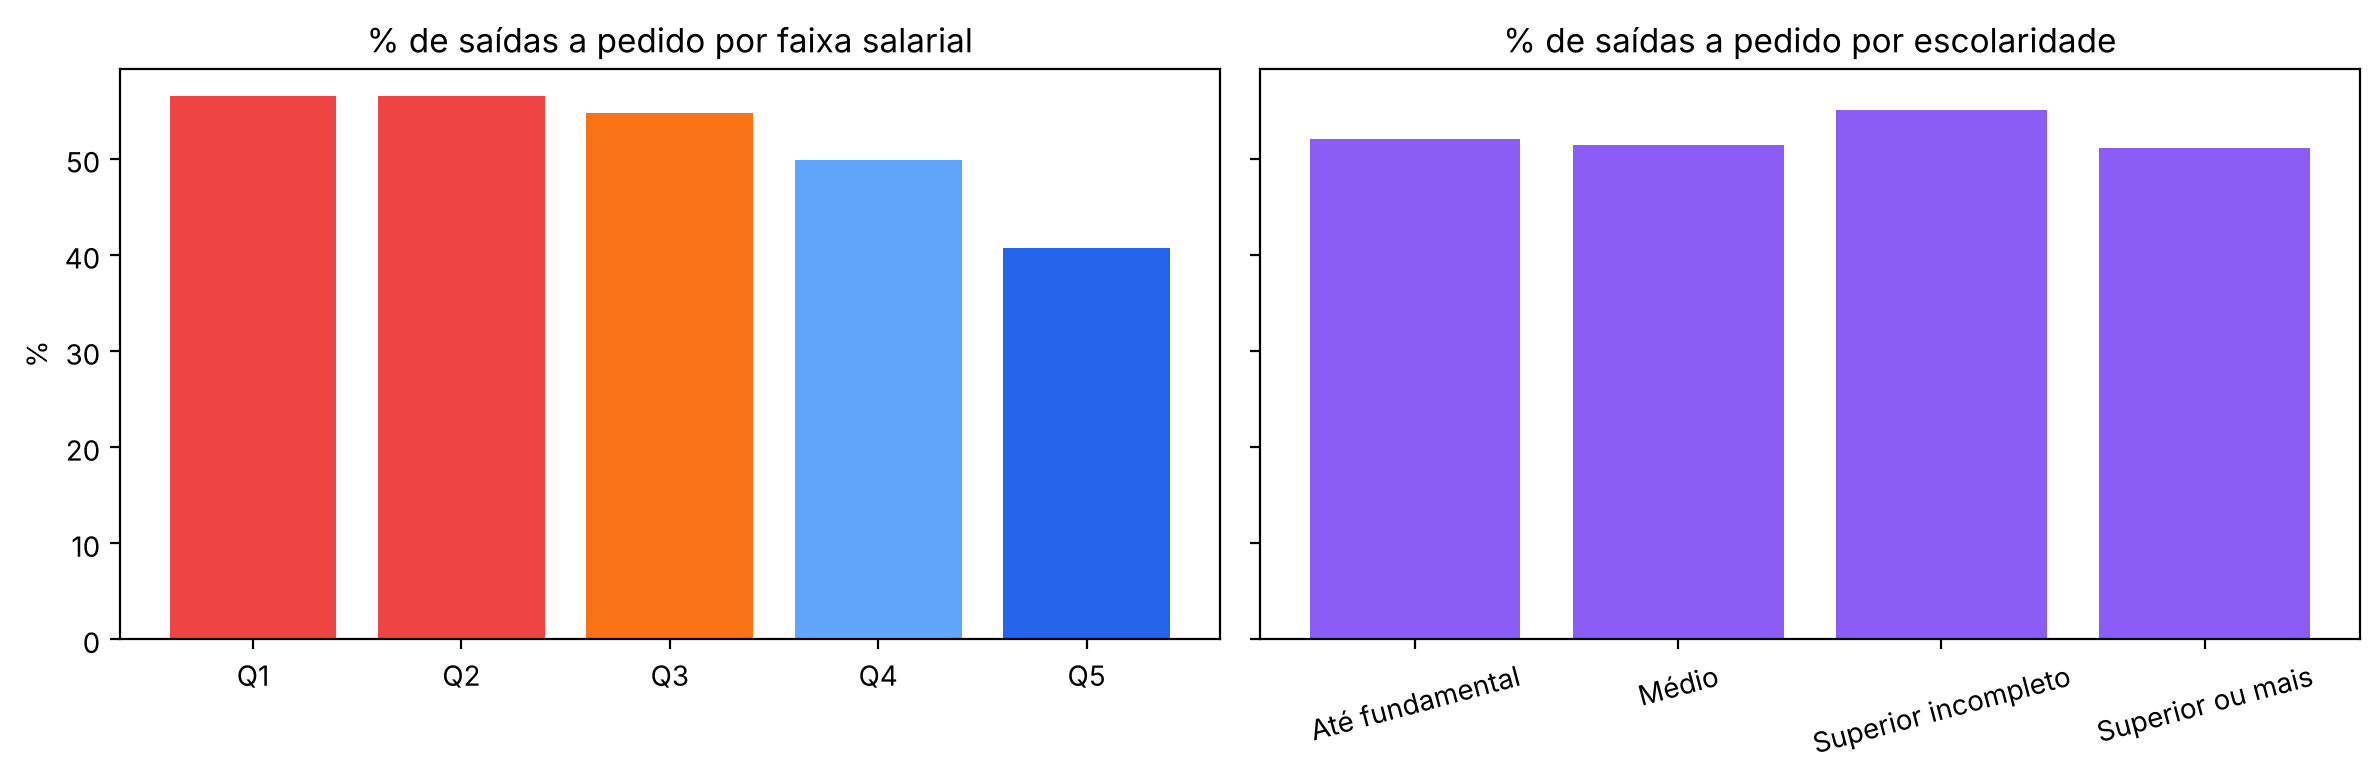

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
q = ps[(ps.faixa_esc == 'Todas') & (ps.quintil_sal != 'Todas')]
ax[0].bar(q['quintil_sal'], q['pct_pedido'] * 100, color=['#EF4444', '#EF4444', '#F97316', '#60A5FA', '#2563EB'])
ax[0].set_title('% de saídas a pedido por faixa salarial'); ax[0].set_ylabel('%')
e = ps[(ps.quintil_sal == 'Todas') & (ps.faixa_esc != 'Todas')]
ax[1].bar(e['faixa_esc'], e['pct_pedido'] * 100, color='#8B5CF6')
ax[1].set_title('% de saídas a pedido por escolaridade'); ax[1].tick_params(axis='x', rotation=15)
plt.tight_layout()

In [17]:
pd.read_csv(P + 'est_logit_pedido.csv')[['termo', 'razao_chance', 'ic95_inf', 'ic95_sup', 'p_valor', 'razao_chance_10pct']].round(3)

,termo,razao_chance,ic95_inf,ic95_sup,p_valor,razao_chance_10pct
0,faixa_esc = Médio,1.050,1.007,1.095,0.023,NaN
1,faixa_esc = Superior incompleto,1.345,1.241,1.458,0.000,NaN
2,faixa_esc = Superior ou mais,1.585,1.456,1.727,0.000,NaN
3,faixa_idade = 14-24,1.095,1.052,1.140,0.000,NaN
4,faixa_idade = 25-29,1.026,0.987,1.066,0.198,NaN
5,faixa_idade = 40-49,0.947,0.909,0.987,0.011,NaN
6,faixa_idade = 50+,0.840,0.785,0.900,0.000,NaN
7,log_sal_cbo,0.417,0.360,0.482,0.000,0.920
8,sal_rel_cbo,0.495,0.459,0.535,0.000,0.935
9,mulher,1.103,1.062,1.146,0.000,NaN


**Leitura:** nas faixas salariais mais baixas (Q1–Q2) 57% das saídas são pedidos; na mais alta (Q5), 41%. Por escolaridade a taxa fica entre 51% e 55%. Na regressão logística (controles: setor, porte, idade, sexo; erros agrupados por CBO), **pagar 10% acima da mediana da mesma ocupação reduz a chance de pedido de demissão em ~6,5%** (razão de chances 0,935), e quem tem superior tem 59% mais chance de pedir para sair: é disputado. Entre os 538 polos município × setor, salário de entrada e % a pedido têm correlação de Spearman de −0,38, e a % de admitidos só com fundamental, de +0,40.

In [18]:
pd.read_csv(P + 'est_correlacoes.csv').query("nivel == 'municipio_setor'")[['var_x', 'var_y', 'rho', 'p_valor', 'n']].round(3)

,var_x,var_y,rho,p_valor,n
6,salario_mediano_adm,pct_pedido_demissao,-0.376,0.000,538
7,salario_mediano_adm,indice_pressao,-0.295,0.000,538
8,salario_mediano_adm,premio_salarial,-0.007,0.876,537
9,salario_mediano_adm,saldo_10k_hab,0.057,0.184,538
10,pct_superior_adm,pct_pedido_demissao,-0.309,0.000,538
11,pct_superior_adm,indice_pressao,-0.283,0.000,538
12,pct_superior_adm,premio_salarial,-0.114,0.008,537
13,pct_superior_adm,saldo_10k_hab,0.007,0.870,538
14,pct_ate_fundamental_adm,pct_pedido_demissao,0.400,0.000,538
15,pct_ate_fundamental_adm,indice_pressao,0.226,0.000,538


## 6. Exportação final
O pipeline grava os indicadores em `data/processed/`, lidos pelo painel Streamlit, e o JSON em `data/processed/api/`.

In [19]:
exportar.main()
sorted(p.name for p in pipeline.OUT.glob('*.csv'))

api/cubo.json                                      5546 linhas
api/salario_hist.json                             19373 linhas
api/escolaridade_cubo.json                         1246 linhas
api/est_correlacoes.json                             50 linhas
api/est_logit_pedido.json                            10 linhas
api/est_pedido_salario_escolaridade.json             30 linhas
api/est_sazonalidade_mensal.json                    432 linhas
api/est_sazonalidade_resumo.json                     36 linhas
api/est_sensibilidade_cenarios.json                  48 linhas
api/est_sensibilidade_pares.json                   3105 linhas
api/est_sensibilidade_pares_regiao.json             503 linhas
api/ind_macrofamilia.json                            17 linhas
api/ind_municipio.json                              294 linhas
api/ind_municipio_setor.json                       3105 linhas
api/ind_regiao_macrofamilia.json                    119 linhas
api/ind_regiao_setor.json                           503

['est_correlacoes.csv',
 'est_logit_pedido.csv',
 'est_pedido_salario_escolaridade.csv',
 'est_sazonalidade_mensal.csv',
 'est_sazonalidade_resumo.csv',
 'est_sensibilidade_cenarios.csv',
 'est_sensibilidade_pares.csv',
 'est_sensibilidade_pares_regiao.csv',
 'ind_macrofamilia.csv',
 'ind_municipio.csv',
 'ind_municipio_setor.csv',
 'ind_regiao_macrofamilia.csv',
 'ind_regiao_setor.csv',
 'log_limpeza.csv',
 'municipios.csv',
 'validacao_schema.csv']

## 6b. Acionamento de parceiros (regras de negócio)
Para cada polo com alerta ou expansão, `dashboard/acionamento.py` escolhe **um** parceiro principal para a FIESC acionar, com a justificativa tirada dos indicadores:
- **Alerta frágil** → só monitorar;
- **Alerta robusto com salário de entrada 3%+ abaixo da mediana do setor** → empresas do polo (revisar piso);
- **Alerta robusto com salário na média** → Awtra (integração, compliance e lideranças);
- **Expansão acelerada com +200 vagas** → UniSENAI (formar para a família de ocupações mais contratada);
- **Secundário:** setor eletrointensivo crescendo +500 vagas → Way2 (eficiência energética).

In [20]:
sys.path.insert(0, '../dashboard')
import acionamento
rs = pd.read_csv(P + 'ind_municipio_setor.csv').merge(
    pd.read_csv(P + 'est_sensibilidade_pares.csv')[['cod_ibge', 'setor', 'estabilidade', 'pct_cenarios_alerta']],
    on=['cod_ibge', 'setor'], how='left')
rs['robusto'] = rs['diagnostico'].isin(acionamento.ALERTAS) & (rs['estabilidade'] == 'Alerta robusto')
ac = acionamento.calcular(ind, rs)
print(ac['parceiro'].value_counts().to_string()); print('Way2 (secundário):', (ac['secundario'] == 'Way2').sum())
ac[ac['parceiro'] != 'Monitorar'][['setor', 'municipio_nome', 'diagnostico', 'parceiro', 'familia_ia', 'porque']].head(10)

parceiro
Monitorar           73
Awtra               25
Empresas do polo    19
UniSENAI             9
Way2 (secundário): 2


,setor,municipio_nome,diagnostico,parceiro,familia_ia,porque
0,Alimentos,Itapiranga,Expansão sob pressão,Awtra,Produção de Base (Linha e Embalagem),O salário já está na média do setor (R$ 2.084)...
1,Veículos automotores,Campo Alegre,Apagão de mão de obra,Empresas do polo,Metalmecânica e Montagem,"Salário de entrada de R$ 2.000, 8% abaixo da m..."
2,Veículos automotores,Sangão,Apagão de mão de obra,Awtra,Metalmecânica e Montagem,O salário já está na média do setor (R$ 2.413)...
3,Vestuário e acessórios,Timbó,Apagão de mão de obra,Awtra,"Têxtil, Vestuário, Couro e Calçados",O salário já está na média do setor (R$ 2.300)...
4,Vestuário e acessórios,Tijucas,Apagão de mão de obra,Awtra,"Têxtil, Vestuário, Couro e Calçados",O salário já está na média do setor (R$ 2.200)...
5,Vestuário e acessórios,Treze de Maio,Apagão de mão de obra,Empresas do polo,"Têxtil, Vestuário, Couro e Calçados","Salário de entrada de R$ 1.837, 12% abaixo da ..."
6,Vestuário e acessórios,Morro da Fumaça,Apagão de mão de obra,Empresas do polo,"Têxtil, Vestuário, Couro e Calçados","Salário de entrada de R$ 1.961, 7% abaixo da m..."
7,Alimentos,Ipumirim,Apagão de mão de obra,Awtra,Produção de Base (Linha e Embalagem),O salário já está na média do setor (R$ 2.054)...
8,Vestuário e acessórios,Rio dos Cedros,Apagão de mão de obra,Awtra,"Têxtil, Vestuário, Couro e Calçados",O salário já está na média do setor (R$ 2.130)...
9,Produtos de metal,Corupá,Apagão de mão de obra,Awtra,Metalmecânica e Montagem,O salário já está na média do setor (R$ 2.456)...


## 7. Conclusões, recomendações e limites
1. **A indústria gira o quadro mas não cresce:** 835.776 movimentações para +1.098 vagas, ou 761 movimentações por vaga criada.
2. **O apagão é de retenção:** 51% das saídas são pedidos do trabalhador. Dos 538 polos município × setor analisados, **44 estão em alerta robusto**, liderados por alimentos em Itapiranga (78% a pedido), veículos em Campo Alegre e Sangão e vestuário em Timbó, Tijucas, Morro da Fumaça e Treze de Maio.
3. **Expansão concentrada:** veículos/equipamentos de transporte em Navegantes (+1.620 e +625) e alimentos em Chapecó (+1.273) e Guatambú (+551).
4. **Salário segura, diploma não:** a taxa de pedido cai de 57% para 41% do menor ao maior salário e quase não varia por escolaridade.
5. **IA:** Agroindústria e Alimentos, Produção de Base e Têxtil/Vestuário perdem 55–60% por pedido e pagam ~R\$ 2,1 mil na entrada.

**Recomendações (FIESC como hub):** UniSENAI com formação nos polos em expansão; empresas do polo revendo piso onde o salário de entrada está abaixo do setor; Awtra com integração e lideranças onde o salário está na média e a rotatividade segue alta; Way2 como apoio em polos eletrointensivos que crescem.

**Limites:** só as bases do desafio entram no diagnóstico; o CAGED mede fluxo, não vagas abertas; só a base MOV foi fornecida; correlação e regressão indicam associação, não causalidade.

## Apêndice bônus: fontes externas (fora das regras do desafio)
Esta seção **não entra no diagnóstico nem nos indicadores principais**. Ela mostra o que muda ao cruzar os mesmos dados com as regiões geográficas imediatas e intermediárias do IBGE (2017), arquivo `data/externos/regioes_ibge.csv`. Se o arquivo for removido, o pipeline roda normalmente e esta célula é pulada.

In [21]:
from pathlib import Path
if Path(P + 'ind_regiao_setor.csv').exists():
    rr = pd.read_csv(P + 'est_sensibilidade_pares_regiao.csv')
    rr = rr[rr['diagnostico'].isin(['Apagão de mão de obra', 'Expansão sob pressão']) & (rr['estabilidade'] == 'Alerta robusto')]
    print(len(rr), 'polos região imediata × setor em alerta robusto (visão bônus)')
    display(rr.nlargest(8, 'movimentacoes')[['regiao_imediata', 'setor', 'movimentacoes', 'pct_pedido_demissao']].round(2))
else:
    print('Fontes externas ausentes: apêndice não executado.')

16 polos região imediata × setor em alerta robusto (visão bônus)


,regiao_imediata,setor,movimentacoes,pct_pedido_demissao
18,Joaçaba - Herval d'Oeste,Alimentos,12233.0,0.68
9,Ibirama - Presidente Getúlio,Vestuário e acessórios,6596.0,0.72
12,São Bento do Sul - Rio Negrinho,Veículos automotores,3671.0,0.63
8,Tubarão,Veículos automotores,2398.0,0.68
17,Caçador,Couro e calçados,1294.0,0.70
11,Ituporanga,Vestuário e acessórios,1139.0,0.64
2,São Bento do Sul - Rio Negrinho,Produtos diversos,778.0,0.56
13,Araranguá,Máquinas e equipamentos,743.0,0.48
